In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/NEW/PRJNA330533")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study,treatment
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,SRR3931522,AMPLICON,252,3881635,PRJNA330533,SAMN05417507,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",2581160,UNIVERISTY OF OKLAHOMA,2011,⋯,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2016-07-24T00:00:00Z,2016-07-19T16:06:00Z,1,H1,SRP078943,healthy
2,SRR3931523,AMPLICON,252,4089942,PRJNA330533,SAMN05417508,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",2784067,UNIVERISTY OF OKLAHOMA,2011,⋯,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2016-07-24T00:00:00Z,2016-07-19T16:06:00Z,1,H10,SRP078943,healthy
3,SRR3931524,AMPLICON,253,3397491,PRJNA330533,SAMN05417517,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",2248934,UNIVERISTY OF OKLAHOMA,2011,⋯,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2016-07-24T00:00:00Z,2016-07-19T16:06:00Z,1,H3,SRP078943,healthy
4,SRR3931525,AMPLICON,252,3420549,PRJNA330533,SAMN05417518,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",2271164,UNIVERISTY OF OKLAHOMA,2011,⋯,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2016-07-24T00:00:00Z,2016-07-19T16:06:00Z,1,H7,SRP078943,healthy
5,SRR3931526,AMPLICON,253,4045943,PRJNA330533,SAMN05417519,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",2682768,UNIVERISTY OF OKLAHOMA,2011,⋯,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2016-07-24T00:00:00Z,2016-07-19T16:06:00Z,1,MC1,SRP078943,mild
6,SRR3931527,AMPLICON,252,3908797,PRJNA330533,SAMN05417520,"MIMS.me,MIGS/MIMS/MIMARKS.human-oral",2555421,UNIVERISTY OF OKLAHOMA,2011,⋯,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2016-07-24T00:00:00Z,2016-07-19T16:06:00Z,1,MC10,SRP078943,mild


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "decription"                     "env_biome"                     
[17] "env_feature"                    "env_material"                  
[19] "Experiment"                     "geo_loc_name_country"          
[21] "geo_loc_name_country_continent" "geo_loc_name"                  
[23] "HOST"                           "Instrument"                    
[25] "lat_lon"                        "Library.Name"                  
[27] "LibraryLayout"                  "LibrarySelection"              
[29] "LibrarySource"                  "Organism"                      
[31] "Platform"                       "ReleaseDate"                   
[33] "create_date"                    "version"                       
[35] "Sample.Name"                    "SRA.Study"                     
[37] "treatment"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = NA,
    Platform = initial_meta$Platform,
    Country = NA,
    Site = 'supragingival dental plaque',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: GTGCCAGCMGCCGCGG; R: TAATCTWTGGGVHCATCAG',
    title = 'Taxonomic and Functional Analyses of the Supragingival Microbiome from Caries-Affected and Caries-Free Hosts',
    Disease_study = "YES",
    Status = initial_meta$treatment,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 37
[1] 37


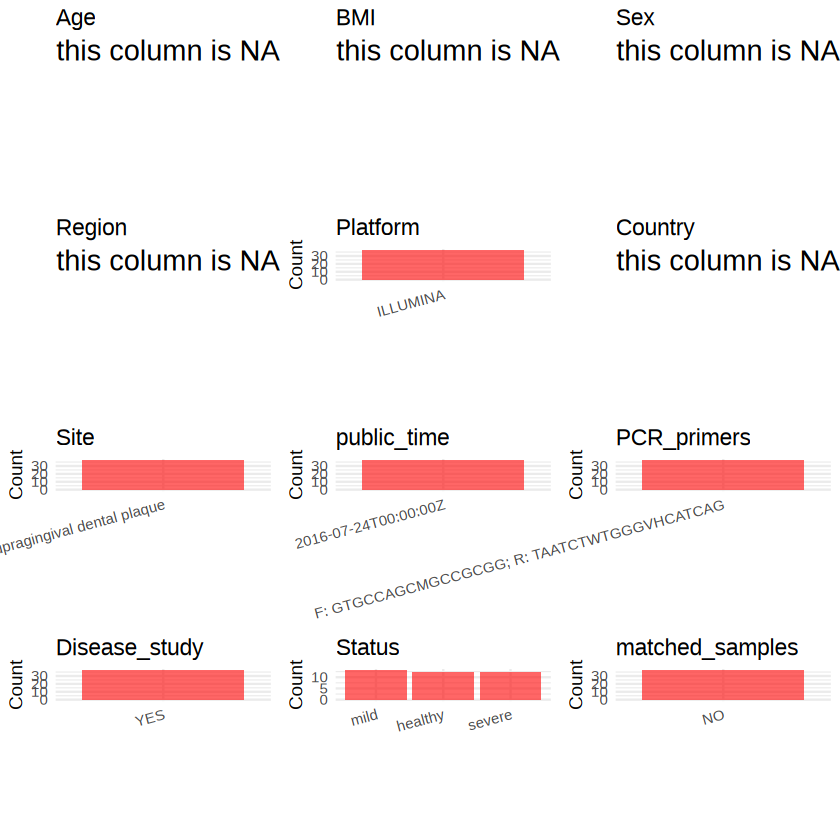

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", 
"Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status", "matched_samples")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/NEW/PRJNA330533/metadata.csv", quote = F)